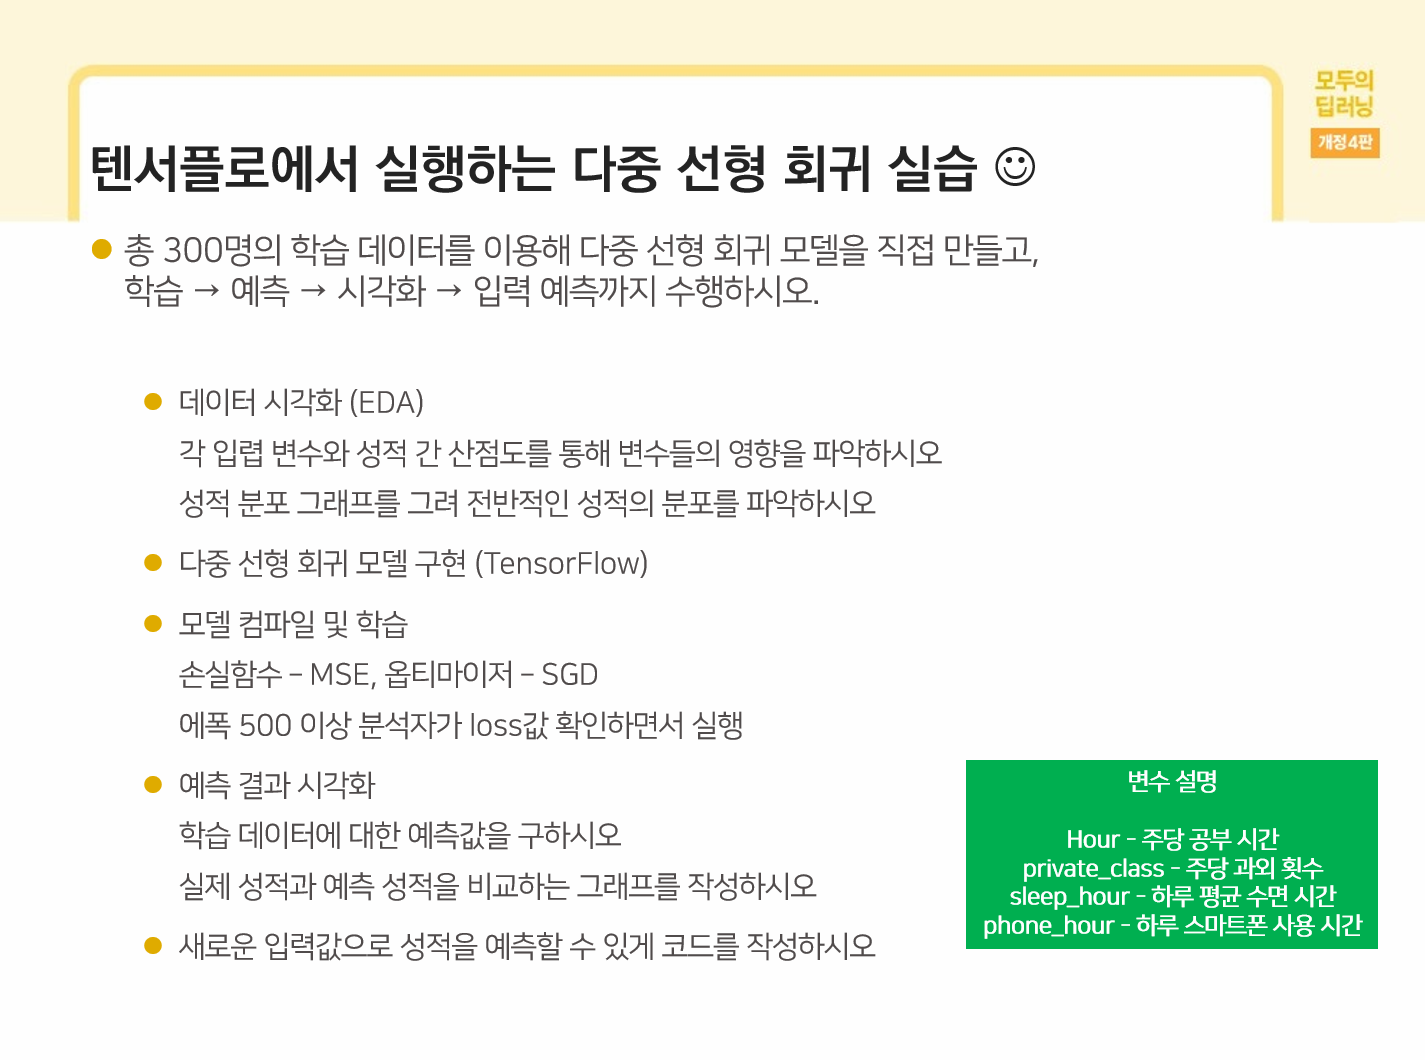

In [2]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor
from wordcloud import WordCloud
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.datasets import cifar10
from sklearn.decomposition import PCA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

plt.rcParams['axes.unicode_minus'] = False

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [9]:
df = pd.read_csv('./ch05_student_score_300.csv')

In [10]:
df

,hour,private_class,sleep_hour,phone_hour,score
0,3.745401,4,6.918281,5.592710,60.338717
1,9.507143,3,4.388673,3.390799,84.443344
2,7.319939,5,8.871974,4.179905,87.430393
3,5.986585,2,8.931054,5.534996,75.459816
4,1.560186,3,7.490809,4.243432,60.402864
...,...,...,...,...,...
295,5.222433,3,6.931149,3.897880,71.111498
296,7.699936,3,6.529443,3.646421,77.713518
297,2.158210,1,7.057271,3.076131,47.653118
298,6.228905,1,4.090551,1.384019,76.913941


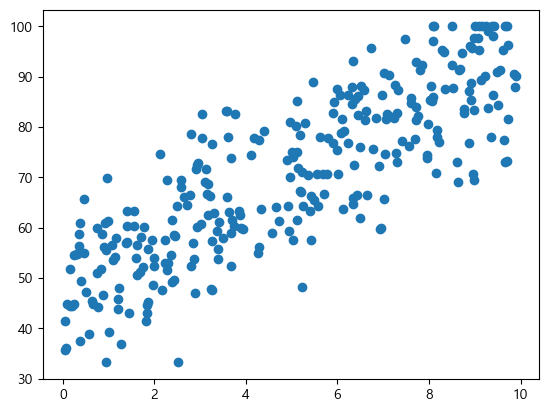

In [11]:
plt.scatter(df['hour'],df['score'])
plt.show()

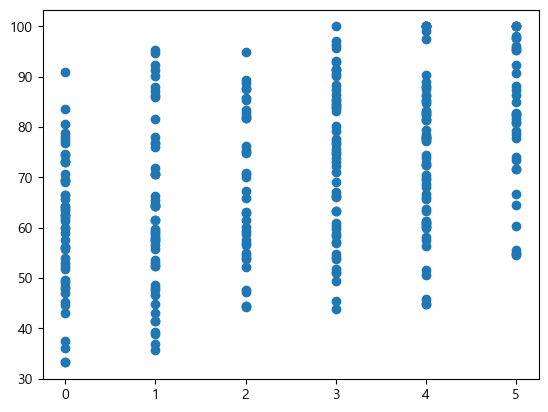

In [12]:
plt.scatter(df['private_class'],df['score'])
plt.show()

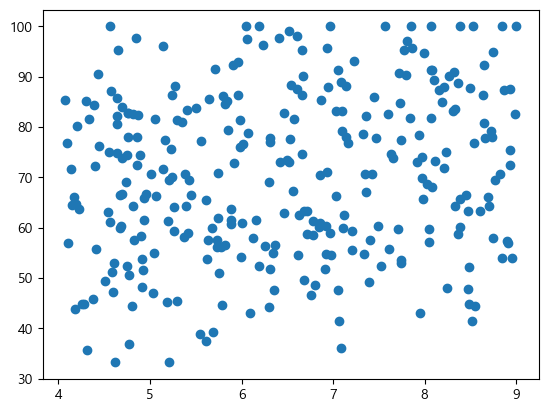

In [13]:
plt.scatter(df['sleep_hour'],df['score'])
plt.show()

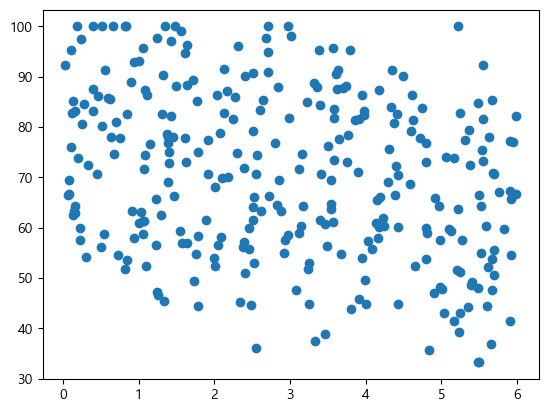

In [14]:
plt.scatter(df['phone_hour'],df['score'])
plt.show()

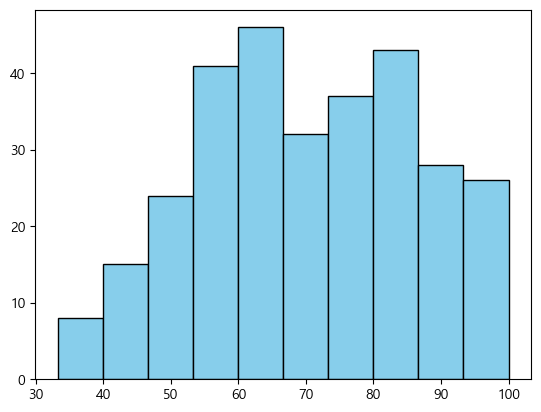

In [15]:
plt.hist(df['score'], bins=10, color='skyblue', edgecolor='black')
plt.show()

In [16]:
model = Sequential()

# 출력 값, 입력 변수, 분석 방법에 맞게끔 모델을 설정합니다. 
model.add(Dense(1, input_dim=1, activation='linear'))

# 오차 수정을 위해 경사 하강법(sgd)을, 오차의 정도를 판단하기 위해 평균 제곱 오차(mse)를 사용합니다. 
model.compile(optimizer='sgd', loss='mse')

# 오차를 최소화하는 과정을 500번 반복합니다.
model.fit(df['hour'], df['score'], epochs=500, verbose=1) #verbose=0은 출력을 생략합니다. 출력을 확인하고 싶은 경우 verbose=1로 설정하세요.

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1285.6354 
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 552.8228 
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 506.0414 
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 978us/step - loss: 466.2286
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 428.7811 
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 392.1875 
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 362.3994 
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 334.5951 
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 317.4612 
Epoch 10/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 290.7901 
Epoch 11/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 269.2161 
Epoch 12/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 255.7214 
Epoch 13/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 233.1991 
Epoch 14/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 221.0848 
Epoch 15/500
10/10 ━━━━━━━━

In [17]:
x=df.drop(columns='score')
y=df['score']

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


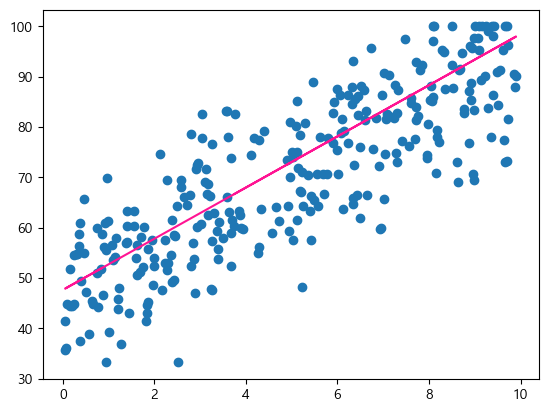

In [ ]:
plt.scatter(df['hour'], df['score'])
plt.plot(df['hour'], model.predict(df['hour']),'deeppink')    # 예측 결과를 그래프로 나타냅니다.
plt.show()
#공부하는 시간이 많아질수록 점수가 증가하는 경향을 보인다.

In [19]:
df.head(0)

,hour,private_class,sleep_hour,phone_hour,score


In [20]:
model = Sequential()

# 출력 값, 입력 변수, 분석 방법에 맞게끔 모델을 설정합니다. 
model.add(Dense(1, input_dim=1, activation='linear'))

# 오차 수정을 위해 경사 하강법(sgd)을, 오차의 정도를 판단하기 위해 평균 제곱 오차(mse)를 사용합니다. 
model.compile(optimizer='sgd', loss='mse')

# 오차를 최소화하는 과정을 500번 반복합니다.
model.fit(df['private_class'], df['score'], epochs=500, verbose=1) #verbose=0은 출력을 생략합니다. 출력을 확인하고 싶은 경우 verbose=1로 설정하세요.

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2497.0850 
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1013.8815 
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 913.0914 
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 835.1003 
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 768.2844
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 705.8482 
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 653.0002 
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 605.7530 
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 564.6898
Epoch 10/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 524.2162 
Epoch 11/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 491.1293 
Epoch 12/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 461.6401 
Epoch 13/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 433.5901 
Epoch 14/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 412.1058 
Epoch 15/500
10/10 ━━━━━━━━━━

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


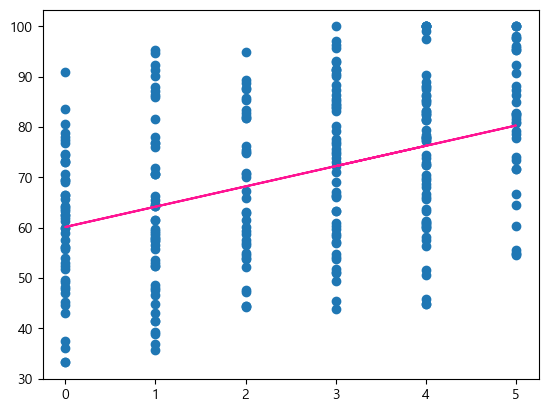

In [ ]:
plt.scatter(df['private_class'], df['score'])
plt.plot(df['private_class'], model.predict(df['private_class']),'deeppink')    # 예측 결과를 그래프로 나타냅니다.
plt.show()
#과외받는 시간만큼 점수가 올라가는 경향이 보인다.
#역시 과외는 시간당 돈을 받으니깐 시간별로 분류해놨네

In [ ]:
model = Sequential()

# 출력 값, 입력 변수, 분석 방법에 맞게끔 모델을 설정합니다. 
model.add(Dense(1, input_dim=1, activation='linear'))

# 오차 수정을 위해 경사 하강법(sgd)을, 오차의 정도를 판단하기 위해 평균 제곱 오차(mse)를 사용합니다. 
model.compile(optimizer='sgd', loss='mse')

# 오차를 최소화하는 과정을 500번 반복합니다.
model.fit(df['sleep_hour'], df['score'], epochs=500, verbose=1) #verbose=0은 출력을 생략합니다. 출력을 확인하고 싶은 경우 verbose=1로 설정하세요.

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 803.2835  
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 413.4918 
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 430.1894
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 417.0938 
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 409.2046 
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 398.6717 
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 399.5531 
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 396.0649 
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 388.8128 
Epoch 10/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 384.1483 
Epoch 11/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 388.5481 
Epoch 12/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 406.2278
Epoch 13/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 382.2403 
Epoch 14/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 380.7661 
Epoch 15/500
10/10 ━━━━━━━━━━━

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


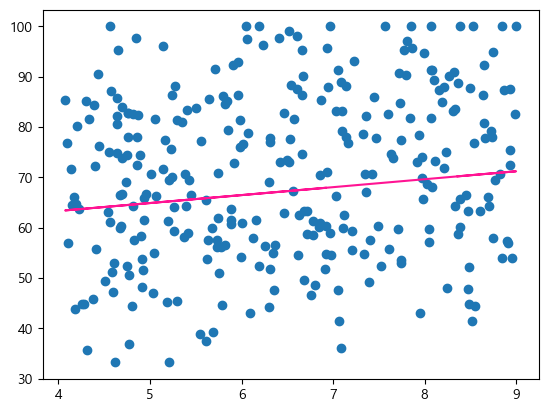

In [ ]:
plt.scatter(df['sleep_hour'], df['score'])
plt.plot(df['sleep_hour'], model.predict(df['sleep_hour']),'deeppink')    # 예측 결과를 그래프로 나타냅니다.
plt.show()
#잠을 많이 잘수록 점수가 잘나오는 경향이 보인다
#역시 사람은 잠을 넉넉하게 자야해

In [24]:
model = Sequential()

# 출력 값, 입력 변수, 분석 방법에 맞게끔 모델을 설정합니다. 
model.add(Dense(1, input_dim=1, activation='linear'))

# 오차 수정을 위해 경사 하강법(sgd)을, 오차의 정도를 판단하기 위해 평균 제곱 오차(mse)를 사용합니다. 
model.compile(optimizer='sgd', loss='mse')

# 오차를 최소화하는 과정을 500번 반복합니다.
model.fit(df['phone_hour'], df['score'], epochs=500, verbose=1) #verbose=0은 출력을 생략합니다. 출력을 확인하고 싶은 경우 verbose=1로 설정하세요.

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2608.2876 
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1507.7523 
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1372.7987 
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1271.5775
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1176.2837
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1083.1302 
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1027.4976 
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 935.4695 
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 868.8024 
Epoch 10/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 807.1222 
Epoch 11/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 753.1984 
Epoch 12/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 705.0620 
Epoch 13/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 664.8475 
Epoch 14/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 622.7631 
Epoch 15/500
10/10 ━━━━━

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


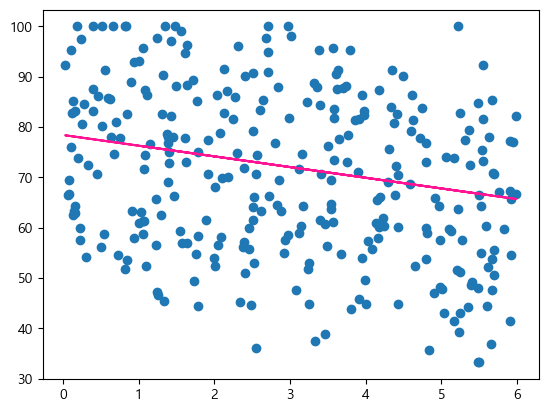

In [ ]:
plt.scatter(df['phone_hour'], df['score'])
plt.plot(df['phone_hour'], model.predict(df['phone_hour']),'deeppink')    # 예측 결과를 그래프로 나타냅니다.
plt.show()
#핸드폰 하는 시간이 커질수록 작아지는 경향이 보인다

In [26]:
import tensorflow as tf

#임의의 시간을 집어넣어 점수를 예측하는 모델을 테스트해 보겠습니다.

hour = 10

input_data = tf.constant([[hour]], dtype=tf.float32)  #쥬피터 노트북 오류를 방지하기 위해 기본 데이터 타입을 float32로 정해 주었습니다.
prediction = model.predict(input_data)[0][0]  

print("%.f시간을 공부할 경우의 예상 점수는 %.02f점입니다" % (hour, prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
10시간을 공부할 경우의 예상 점수는 57.19점입니다


In [27]:
model = Sequential()

# 출력 값, 입력 변수, 분석 방법에 맞게끔 모델을 설정합니다. 
model.add(Dense(1, input_dim=4, activation='linear'))

# 오차 수정을 위해 경사 하강법(sgd)을, 오차의 정도를 판단하기 위해 평균 제곱 오차(mse)를 사용합니다. 
model.compile(optimizer='sgd', loss='mse')

# 오차를 최소화하는 과정을 500번 반복합니다.
model.fit(x, y, epochs=500, verbose=1) #verbose=0은 출력을 생략합니다. 출력을 확인하고 싶은 경우 verbose=1로 설정하세요.

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1074.7422 
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 76.8685 
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 86.8106  
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 61.2331 
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 57.4247 
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 57.2722
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 57.1947 
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 60.2512 
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 59.7663
Epoch 10/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 56.2925 
Epoch 11/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 69.2120  
Epoch 12/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 73.2245 
Epoch 13/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 54.9871 
Epoch 14/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 69.4558 
Epoch 15/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


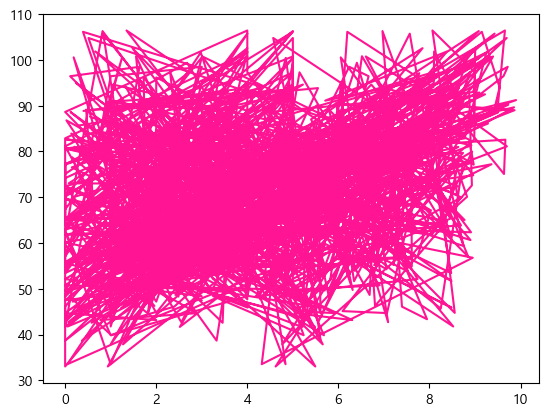

In [ ]:
plt.plot(x, model.predict(x),'deeppink')
plt.show()

In [36]:
import tensorflow as tf
#임의의 학습 시간과 과외 시간을 집어넣어 점수를 예측하는 모델을 테스트해 보겠습니다.

hour = 9.50714306409916
private_class = 3
sleep_hour = 4.38867318482492
phone_hour = 3.39079910153525

input_data = tf.constant([[hour, private_class, sleep_hour, phone_hour]])  
prediction = model.predict(input_data)[0][0]  

print("%.f시간을 공부하고 %.f시간의 과외를 받으며 %.f시간 자고, %.f시간 핸드폰을 할 경우  예상 점수는 %.02f점입니다" % (hour, private_class, sleep_hour, phone_hour, prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
10시간을 공부하고 3시간의 과외를 받으며 4시간 자고, 3시간 핸드폰을 할 경우  예상 점수는 88.52점입니다


In [38]:
import tensorflow as tf
#임의의 학습 시간과 과외 시간을 집어넣어 점수를 예측하는 모델을 테스트해 보겠습니다.

a=0
while(1):
    a = input("순서대로 공부시간, 과외시간, 수면시간, 핸드폰한 시간을 입력하시오 (그만하고싶으면 -1을 입력하세요)")
    if a.strip() == "-1":
        print("프로그램을 종료합니다.")
        break
    try:
        hour, private_class, sleep_hour, phone_hour = map(float, a.split())
    except ValueError:
        print("올바른 형식으로 입력해주세요. 예: 4 2 7 3 (또는 종료시 -1)\n")
    b= hour + sleep_hour + phone_hour + private_class
    if b>24:
        print("하루가 24시간인데 24보다 큽니다.")
        continue
    input_data = tf.constant([[hour, private_class, sleep_hour, phone_hour]])  
    prediction = model.predict(input_data)[0][0]  
    if(prediction <= 100):
        print("%.f시간을 공부하고 %.f시간의 과외를 받으며 %.f시간 자고, %.f시간 핸드폰을 할 경우  예상 점수는 %.02f점입니다" % (hour, private_class, sleep_hour, phone_hour, prediction))
    else:
        print("%.f시간을 공부하고 %.f시간의 과외를 받으며 %.f시간 자고, %.f시간 핸드폰을 할 경우  예상 점수는 100점입니다" % (hour, private_class, sleep_hour, phone_hour))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
9시간을 공부하고 4시간의 과외를 받으며 7시간 자고, 0시간 핸드폰을 할 경우  예상 점수는 100점입니다
프로그램을 종료합니다.


In [32]:
df.head(0)

,hour,private_class,sleep_hour,phone_hour,score
